# Graph inputs as notebook parameters

Input nodes become typed variables at the top of the code. In the multi-cell layout they land in one cell tagged parameters, so papermill can override them.

**When to use it.** Notebooks you re-run with different settings, by hand or from a scheduler such as papermill.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

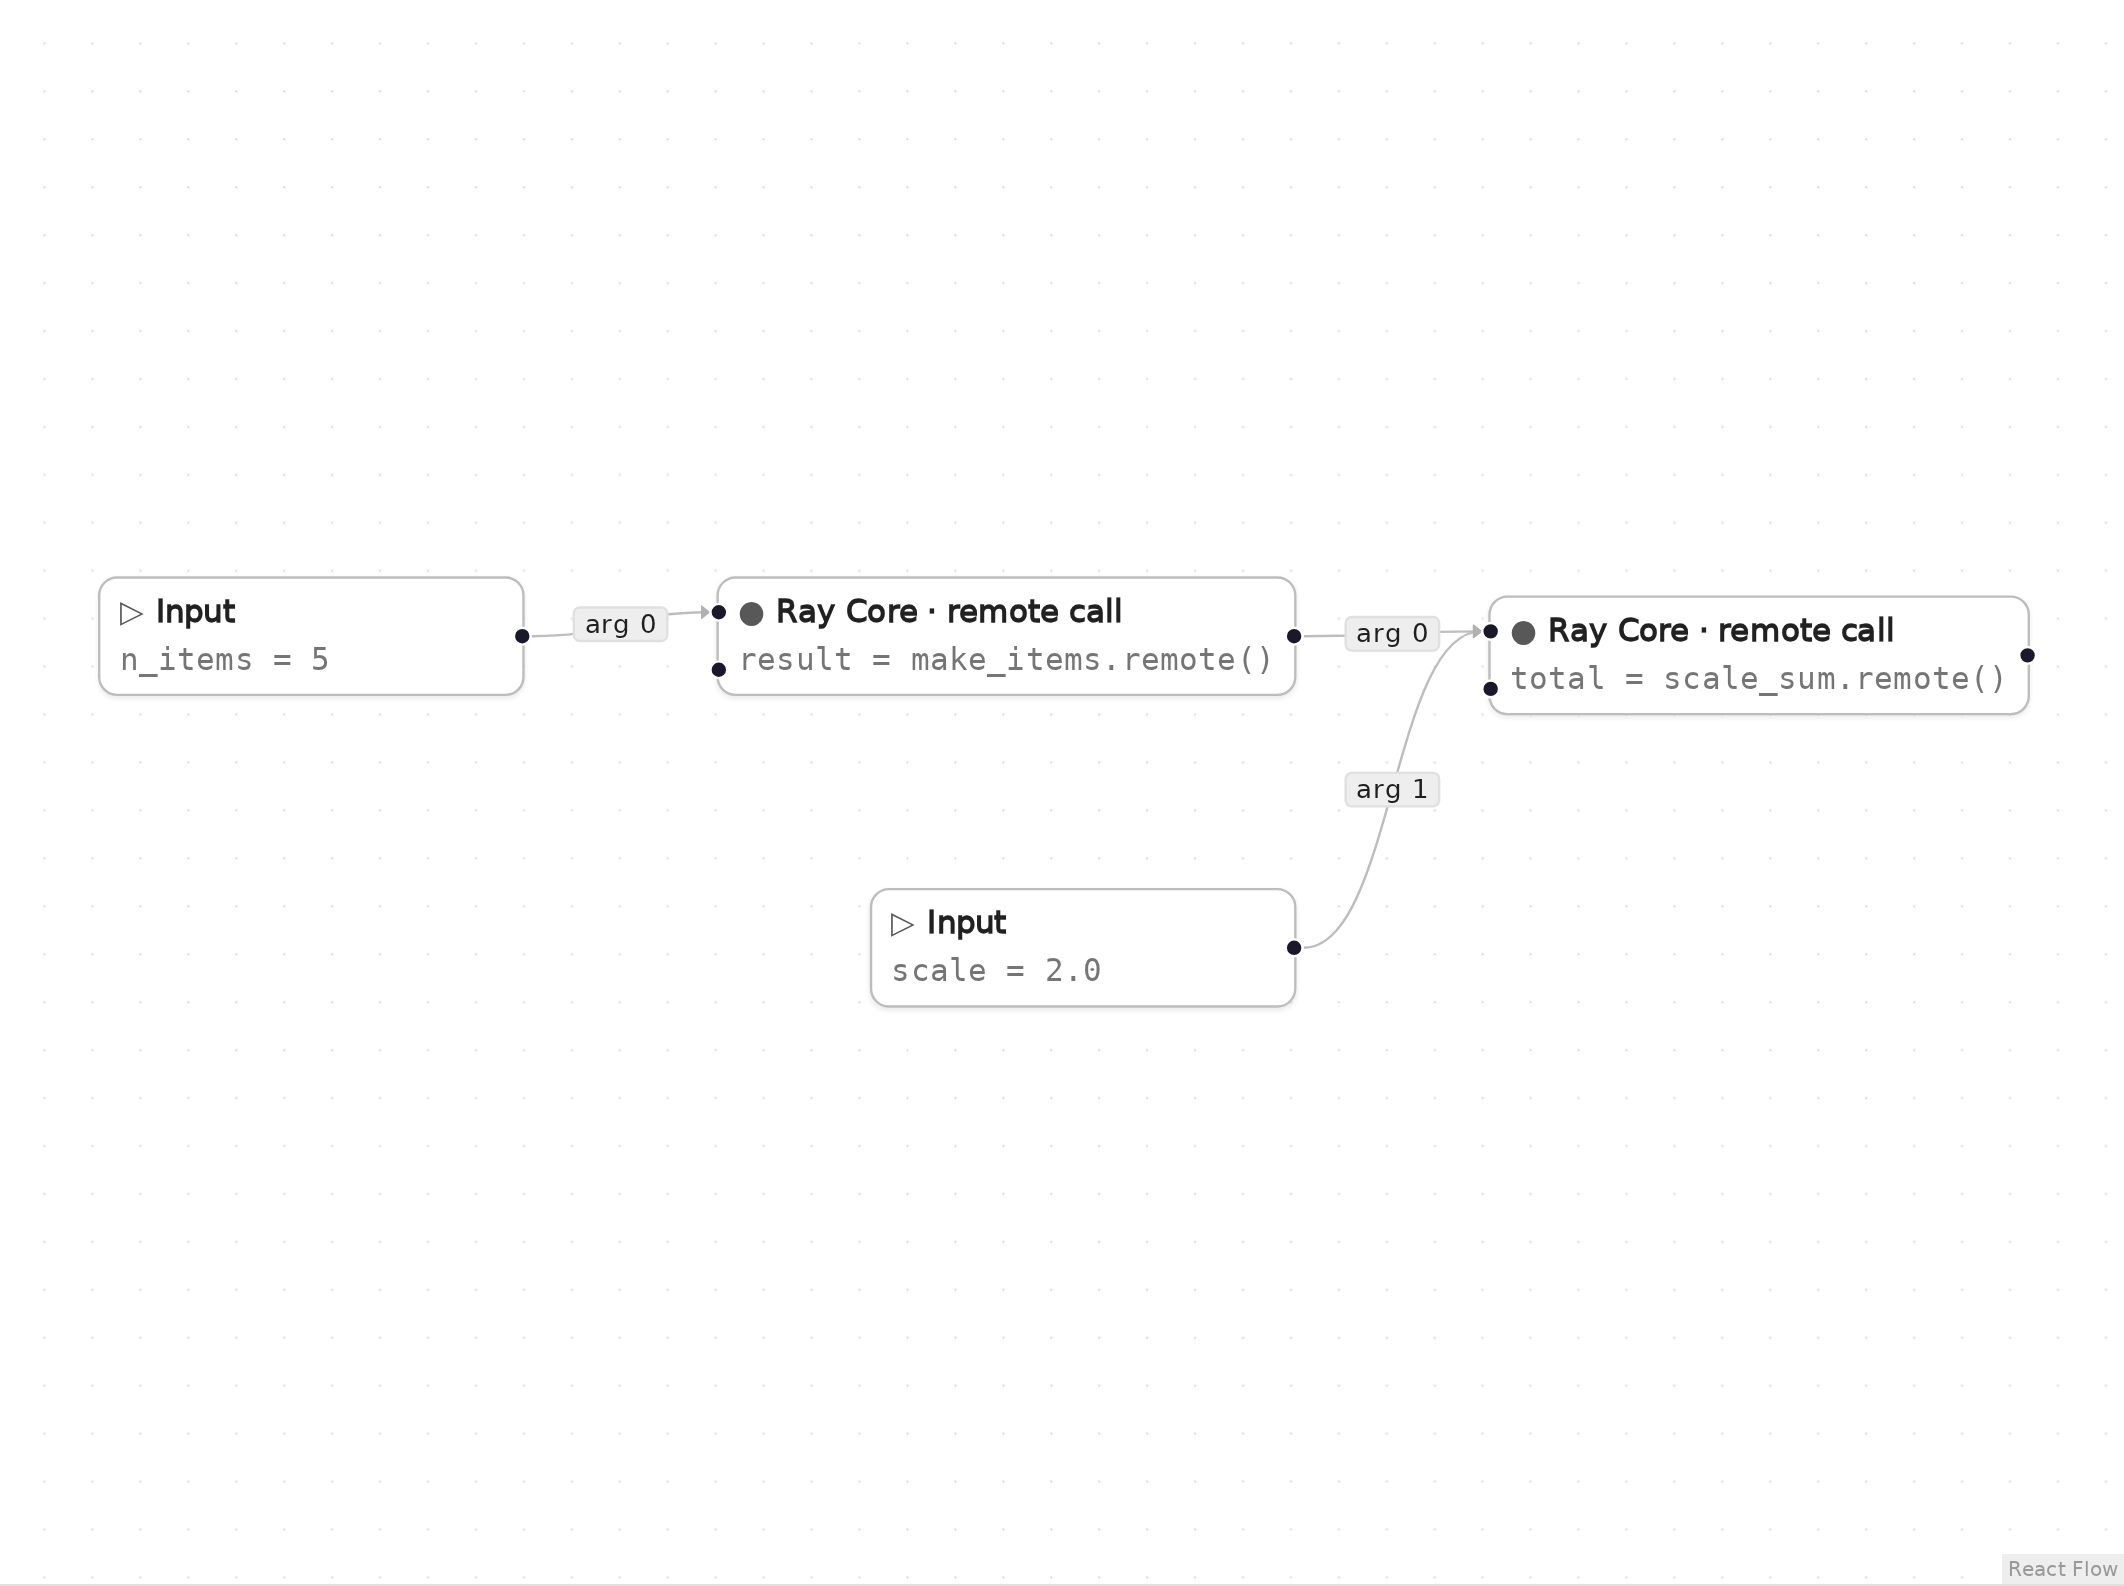

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
def make_items(n):
    return list(range(n))


def scale_sum(items, scale):
    return sum(items) * scale

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

# Inputs
n_items: int = 5
scale: float = 2.0

_n1 = ray.remote(make_items).remote(n_items)
_n2 = ray.remote(scale_sum).remote(_n1, scale)
total = ray.get(_n2)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert total == 20.0, total
print("total =", total)

total = 20.0


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Input** (node `i1`, line 9)

```python
n_items: int = 5
```

An int input with default 5. It becomes the annotated variable n_items.

**Input** (node `i2`, line 10)

```python
scale: float = 2.0
```

A float input with default 2.0.

**Remote task** (node `n1`, line 12)

```python
_n1 = ray.remote(make_items).remote(n_items)
```

make_items receives the n_items value.

**Remote task** (node `n2`, lines 13–14)

```python
_n2 = ray.remote(scale_sum).remote(_n1, scale)
total = ray.get(_n2)
```

scale_sum receives the ObjectRef from make_items and the scale value; Ray resolves the ref first.

## Other ways the builder can emit this graph

The builder can emit the same graph in other forms. They are shown here as text and are not run by this notebook.

### One cell per node

The builder can also split the generated code into one notebook cell per node, so each step can be re-run on its own. The inputs cell carries the `parameters` tag, so a notebook runner such as papermill can override the inputs.

*Cell 1*

```python
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()
```

*Cell 2 (tag: `parameters`)*

```python
# Inputs
n_items: int = 5
scale: float = 2.0
```

*Cell 3*

```python
_n1 = ray.remote(make_items).remote(n_items)
```

*Cell 4*

```python
_n2 = ray.remote(scale_sum).remote(_n1, scale)
total = ray.get(_n2)
```

### As a standalone script (`input_parameters.py`)

The builder can export the graph as a Python module: the user functions are copied in and the Ray calls go under `if __name__ == "__main__":`. It was run as a script on Ray 2.55.1. The builder also writes a comment block of its own export notes at the top of the file; it is left out here.

```python
# Generated with Eugo's visual Ray builder

import ray

def make_items(n):
    return list(range(n))


def scale_sum(items, scale):
    return sum(items) * scale

if __name__ == "__main__":
    ray.init()

    # Inputs
    n_items: int = 5
    scale: float = 2.0

    _n1 = ray.remote(make_items).remote(n_items)
    _n2 = ray.remote(scale_sum).remote(_n1, scale)
    total = ray.get(_n2)
    ray.shutdown()
```

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()